# Checks for the per-feature ZOIB linking function (`linking.py`)

Visual versions of the checks run on `linking.py` before wiring it into Laplace/VBMC. Study 9,
preregistered data, **raw** ratings (no half-bin nudge).

**Model.** As in the original linking function, every feature j has its own two components, mixed by
coherence: `p(r) = pz1·ZOIB_kl,j(r) + (1 − pz1)·ZOIB_nkl,j(r)`. Each component is a zero/one-inflated Beta:
- P(r = 0) = π0_c,j, P(r = 100) = π1_c,j,
- otherwise (1 − π0_c,j − π1_c,j) · Beta(r | m_c,j, κ_c,j).

That's 8 parameters per feature and nothing shared across features. 50s are handled by the Beta part.
Constraints: single-peaked Betas (a, b > 1), κ ≤ 100, m_kl ≥ m_nkl, π1_kl ≥ π1_nkl, π0_kl ≤ π0_nkl.
The fit is penalized ML with a weak Beta(1.5, 1.5) penalty on each π.

The linking is fit at two **fixed** θ values from earlier fits (nothing here refits θ):
- **current θ** (ls 0.98, speaker β 0.91): coherence is flat, ≈ 0.57 everywhere;
- **old θ** (ls 0.21, speaker β 16): coherence varies by condition, 0.41–0.77.

1. Fit reliability
2. Point masses vs the observed rates of 0 and 100 (and what happens at 50)
3. Constraints
4. Each component is a proper distribution
5. The fitted linking functions against the data
6. Predicted vs empirical mean ratings

In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plot_style
plot_style.use_lexend()          # Lexend everywhere (DejaVu Sans fills in σ/β)
from matplotlib.lines import Line2D
import jax
import jax.numpy as jnp
from scipy.optimize import minimize
from scipy.stats import beta as sbeta
from scipy.integrate import quad

import inference as inf
import linking as lk

geom = inf.load_geometry()
features, trait, J = geom['test_feature_names'], geom['test_trait'], geom['J']
CONDS = list(inf.CONDITIONS)
raw, _ = inf.load_responses('../../data/study9_prereg.csv', clip_interior=False)
K = {c: np.round(np.asarray(raw[c]) * 100).astype(int) for c in CONDS}    # integer slider values

THETAS = {}
for name, npz in [('current θ', 'results/study9-fit/fitted-link-shapes.npz'),
                  ('old θ', 'results/study9-fit/fitted-link-shapes-old-beta16.npz')]:
    ls, mu0, sig, b = [float(v) for v in np.load(npz)['theta']]
    pz1 = {c: np.asarray(v) for c, v in inf.prior_pz1_modes(geom, ls, mu0, sig, beta_speaker=b).items()}
    THETAS[name] = dict(theta=(ls, mu0, sig, b), pz1=pz1)
    print(f"{name}: ls={ls:.3f} mu_0={mu0:+.3f} sigma={sig:.3f} speaker beta={b:.3f}  "
          f"pz1 range {min(v.min() for v in pz1.values()):.3f}-{max(v.max() for v in pz1.values()):.3f}")

COND_COLOR = {'physical': '#2a78d6', 'diet': '#eb6834', 'personality': '#1baf7a', 'heterogeneous': '#eda100'}
METHOD_COLOR = {'plain joint multi-start': '#eb6834', 'batched per-feature fit': '#2a78d6'}
CLS_COLOR = {'kl': '#2a78d6', 'nkl': '#eb6834'}
TEXT_1, TEXT_2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': MUTED, 'axes.labelcolor': TEXT_2, 'xtick.color': TEXT_2, 'ytick.color': TEXT_2,
    'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'legend.frameon': False,
})
def grid_y(ax):
    ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
def grid_xy(ax):
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)

current θ: ls=0.978 mu_0=+0.006 sigma=0.526 speaker beta=0.907  pz1 range 0.562-0.575
old θ: ls=0.205 mu_0=-0.397 sigma=0.782 speaker beta=16.035  pz1 range 0.408-0.769


## 1. Fit reliability

Penalized objective reached from each start, relative to the best found (0 = best).

- **Plain joint multi-start** (orange): 24 random starts, each optimizing all 120 parameters at once with
  scipy L-BFGS-B.
- **Batched per-feature fit** (blue, what `linking.fit` does): every feature is fit independently from 17
  starts in one batched Newton call, keeping the best start per feature. One point per random seed (4 seeds).

Also timed: one batched fit (after the one-time compile).

In [2]:
_total = jax.jit(jax.value_and_grad(
    lambda x, r, cls, th: jnp.sum(jax.vmap(lk._feature_objective, in_axes=(0, 1, 1, 1))(x.reshape(J, lk.N_PAR), r, cls, th))))
rows, fits, timing = [], {}, {}
for name, T in THETAS.items():
    r, cls, th, R = lk.stack(raw, T['pz1'])
    def f(x):
        v, g = _total(jnp.asarray(x), r, cls, th)
        return float(v), np.asarray(g)
    base = lk.data_inits(R, cls)[0].ravel()
    rng = np.random.default_rng(0)
    for i in range(24):
        res = minimize(f, base + rng.normal(0, 1.5, base.shape), jac=True, method='L-BFGS-B', options={'maxiter': 5000})
        rows.append({'theta': name, 'method': 'plain joint multi-start', 'objective': float(res.fun)})
    lk.fit(raw, T['pz1'])                                   # compile
    for seed in range(4):
        t0 = time.time()
        x, _nll = lk.fit(raw, T['pz1'], seed=seed)
        timing.setdefault(name, []).append(time.time() - t0)
        rows.append({'theta': name, 'method': 'batched per-feature fit', 'objective': float(f(x.ravel())[0])})
        if seed == 0:
            fits[name] = x
print({k: f"{np.mean(v):.2f}s per batched fit" for k, v in timing.items()})
rel = pd.DataFrame(rows)
rel['objective - best'] = rel['objective'] - rel.groupby('theta')['objective'].transform('min')
rel.groupby(['theta', 'method'])['objective - best'].describe()[['count', 'min', '50%', 'max']].round(3)

{'current θ': '1.04s per batched fit', 'old θ': '0.89s per batched fit'}


count    min    50%     max
theta     method                                              
current θ batched per-feature fit    4.0  0.000  0.000   0.000
          plain joint multi-start   24.0  0.847  3.073  12.476
old θ     batched per-feature fit    4.0  0.000  0.000   0.000
          plain joint multi-start   24.0  0.003  5.190  13.638

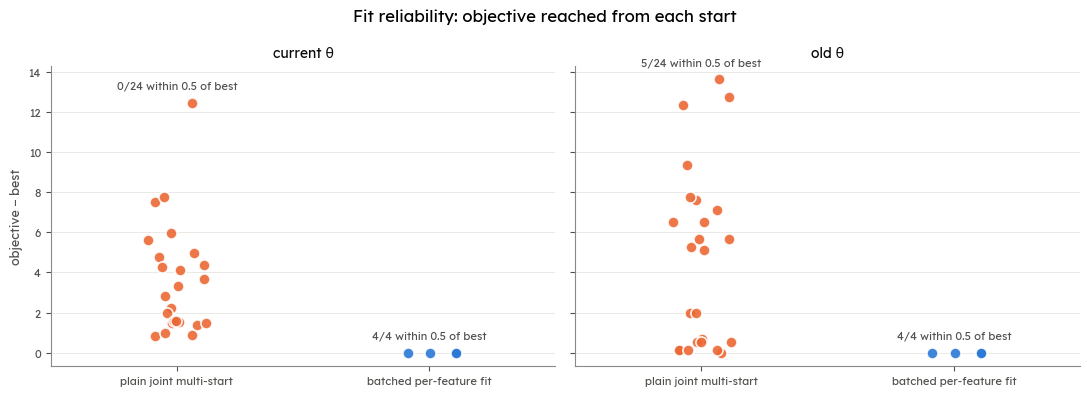

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, name in zip(axes, THETAS):
    for k, m in enumerate(METHOD_COLOR):
        y = rel[(rel.theta == name) & (rel.method == m)]['objective - best'].values
        x = k + np.random.default_rng(1).uniform(-0.12, 0.12, len(y))
        ax.plot(x, y, 'o', color=METHOD_COLOR[m], ms=8, mec='white', mew=1.2, alpha=0.9)
        ax.annotate(f"{int(np.sum(y < 0.5))}/{len(y)} within 0.5 of best", (k, y.max()), xytext=(0, 10),
                    textcoords='offset points', ha='center', fontsize=8, color=TEXT_2)
    ax.set_xticks([0, 1]); ax.set_xticklabels(list(METHOD_COLOR)); ax.set_xlim(-0.5, 1.5)
    ax.set_title(name, color=TEXT_1); grid_y(ax)
axes[0].set_ylabel('objective − best')
fig.suptitle('Fit reliability: objective reached from each start', fontsize=12)
fig.tight_layout(); plt.show()

## 2. Point masses vs observed rates of 0 and 100

One point per condition × feature cell: observed share of exact-0 and exact-100 answers vs the fitted
P(0) = pz1·π0_kl,j + (1 − pz1)·π0_nkl,j and P(100) likewise. Points on the diagonal = the point masses
match the data cell by cell. Differences between features come from the per-feature πs; differences
between conditions for the same feature can only come from coherence.

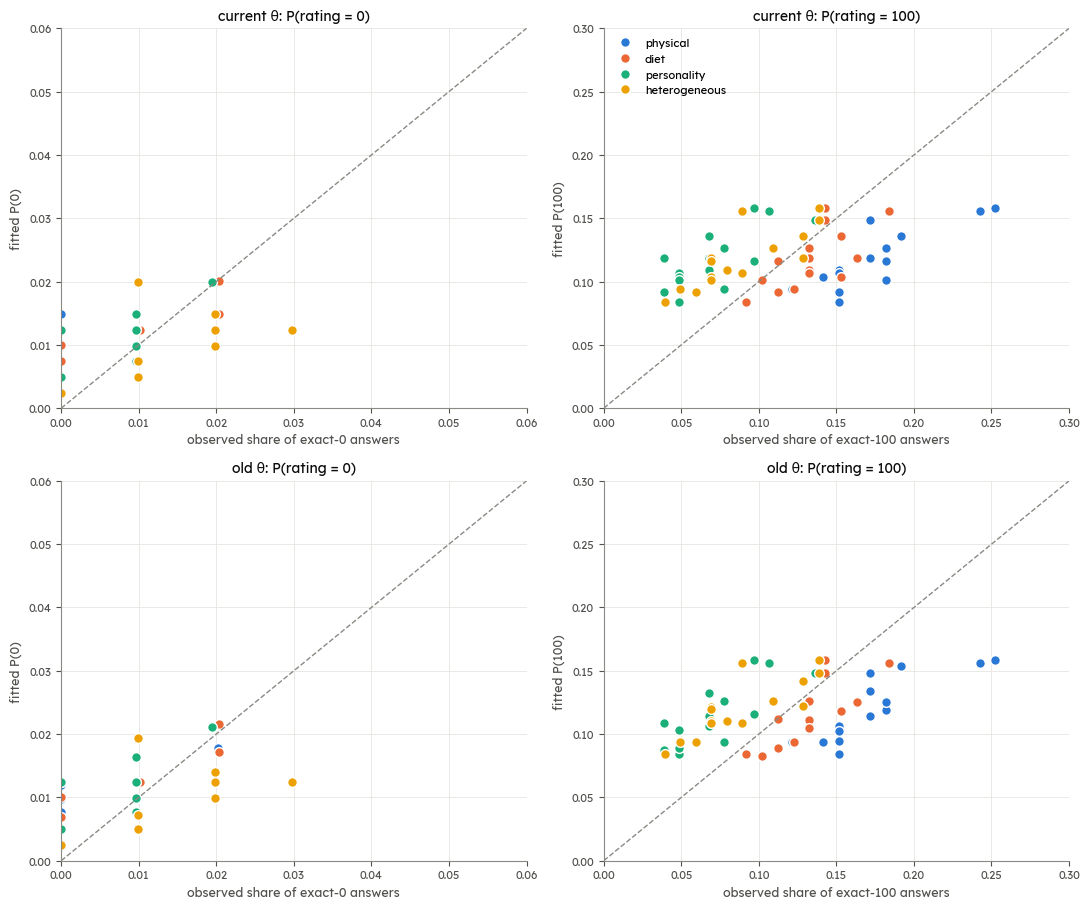

In [4]:
P = {name: lk.params_to_numpy(lk.unpack(jnp.asarray(x))) for name, x in fits.items()}
fig, axes = plt.subplots(len(THETAS), 2, figsize=(11, 4.6 * len(THETAS)))
for r_i, name in enumerate(THETAS):
    p, pz1 = P[name], THETAS[name]['pz1']
    for k_i, (val, key, lim) in enumerate([(0, 'pi0', 0.06), (100, 'pi1', 0.3)]):
        ax = axes[r_i, k_i]
        for c in CONDS:
            obs = np.mean(K[c] == val, axis=0)
            fit = pz1[c] * p[key + '_kl'] + (1 - pz1[c]) * p[key + '_nkl']
            ax.plot(obs, fit, 'o', color=COND_COLOR[c], ms=7, mec='white', mew=1, label=c)
        ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls='--'); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_xlabel(f'observed share of exact-{val} answers'); ax.set_ylabel(f'fitted P({val})')
        ax.set_title(f"{name}: P(rating = {val})", color=TEXT_1); grid_xy(ax)
axes[0, 1].legend(loc='upper left')
fig.tight_layout(); plt.show()

**What happens at 50.** 50 is not a point mass in this model, so exact-50 answers are scored by the
Beta densities. For each feature: observed share of exact-50 answers vs the model's probability of the
single slider value 50 (density at 0.5 × 0.01, averaged over conditions).

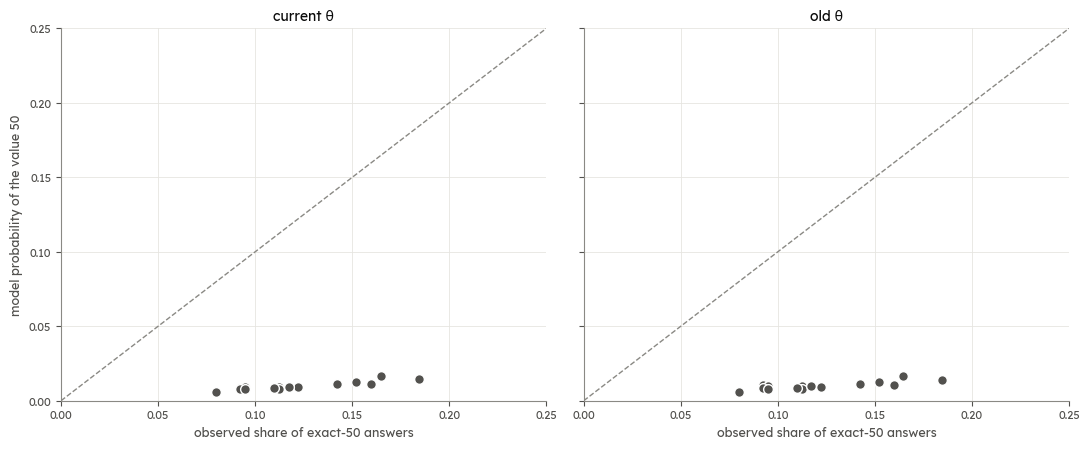

In [5]:
fig, axes = plt.subplots(1, len(THETAS), figsize=(11, 4.6), sharex=True, sharey=True)
for ax, name in zip(axes, THETAS):
    p, pz1 = P[name], THETAS[name]['pz1']
    Kall = np.concatenate([K[c] for c in CONDS])
    obs = np.mean(Kall == 50, axis=0)
    dens = lambda c: (1 - p['pi0_' + c] - p['pi1_' + c]) * sbeta.pdf(0.5, p['a_' + c], p['b_' + c]) * 0.01
    mod = np.mean([pz1[c] * dens('kl') + (1 - pz1[c]) * dens('nkl') for c in CONDS], axis=0)
    ax.plot(obs, mod, 'o', color=TEXT_2, ms=7, mec='white')
    ax.plot([0, 0.25], [0, 0.25], color=MUTED, lw=1, ls='--'); ax.set_xlim(0, 0.25); ax.set_ylim(0, 0.25)
    ax.set_xlabel('observed share of exact-50 answers'); ax.set_title(name, color=TEXT_1); grid_xy(ax)
axes[0].set_ylabel('model probability of the value 50')
fig.tight_layout(); plt.show()

## 3. Constraints

Top row: ordered Beta means (m_kl ≥ m_nkl) and ordered point masses (π1_kl ≥ π1_nkl; π0_nkl ≥ π0_kl).
Every point must be on or above the dashed diagonal. Bottom row: single-peaked (a, b > 1), concentration
against the cap, and how many features have (nearly) equal classes. Points **on** a diagonal are features
where the two classes are equal in that respect, so coherence can't act through it.

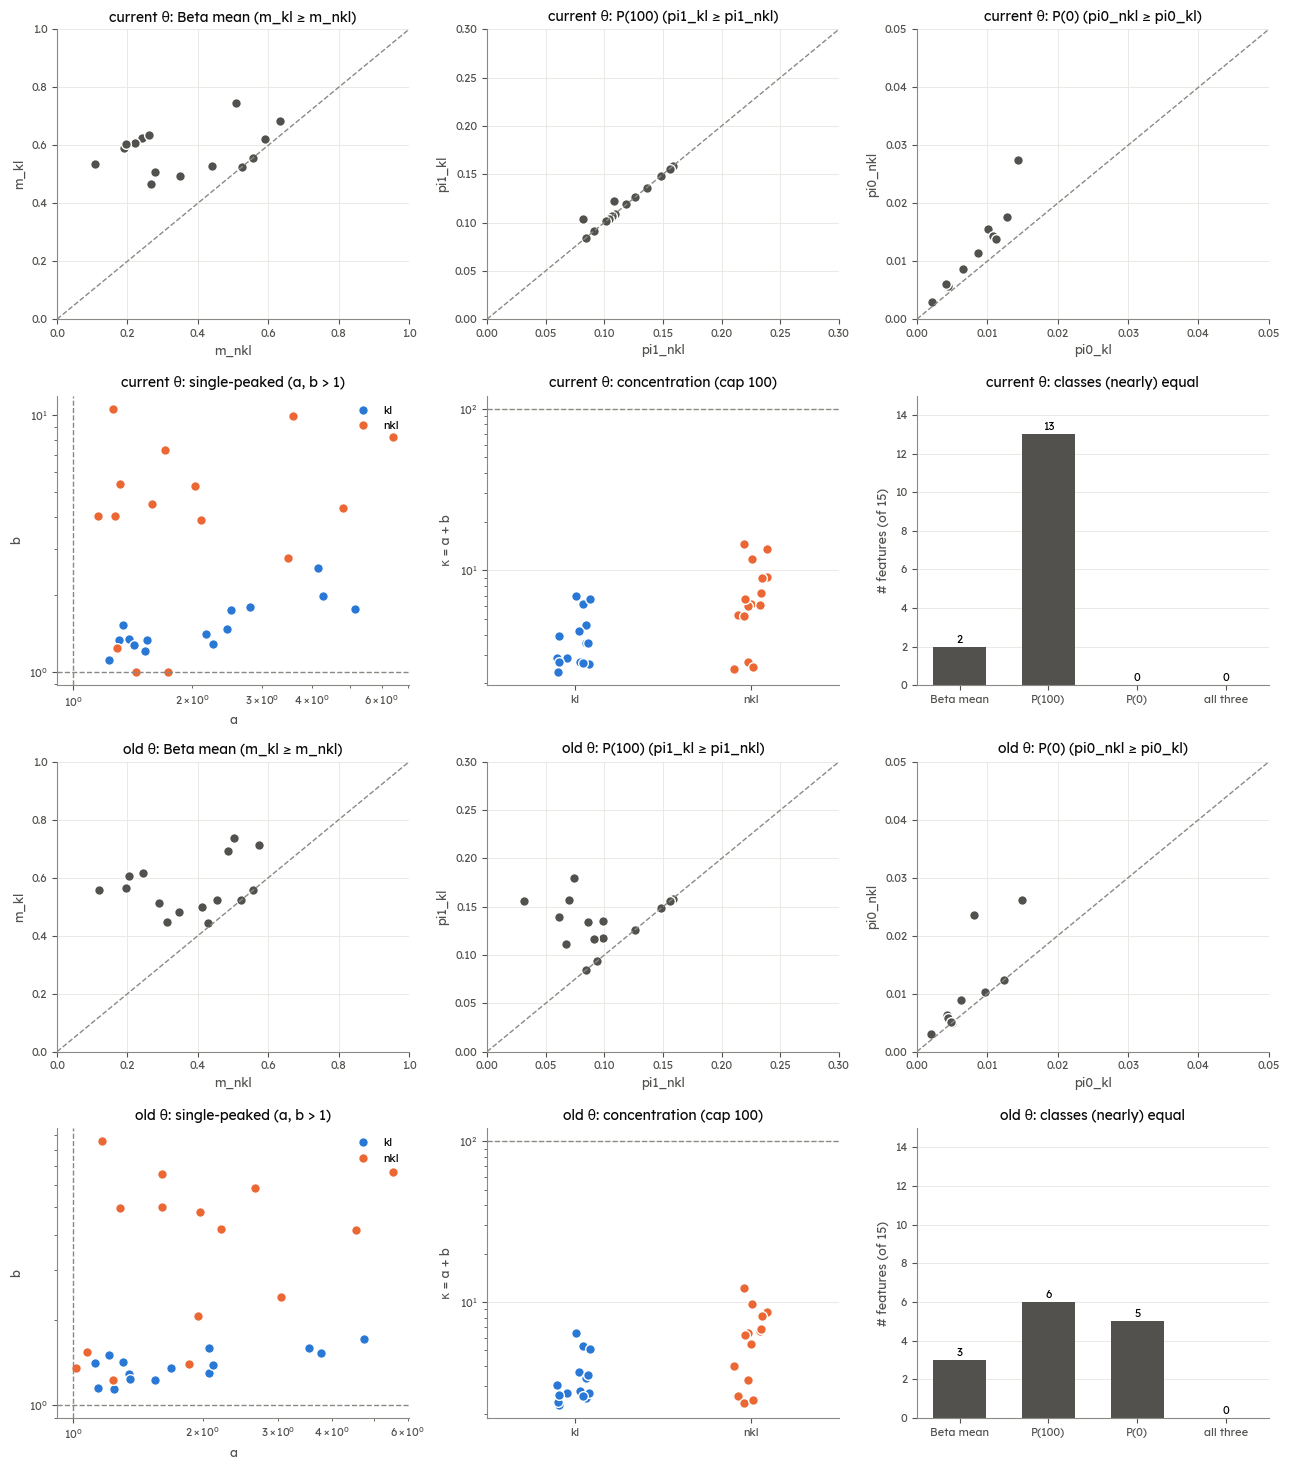

In [6]:
fig, axes = plt.subplots(2 * len(THETAS), 3, figsize=(13, 7.4 * len(THETAS)))
for r_i, name in enumerate(THETAS):
    p = P[name]
    top, bot = axes[2 * r_i], axes[2 * r_i + 1]
    for ax, (xk, yk, lim, lab) in zip(top, [('m_nkl', 'm_kl', 1.0, 'Beta mean'), ('pi1_nkl', 'pi1_kl', 0.3, 'P(100)'),
                                           ('pi0_kl', 'pi0_nkl', 0.05, 'P(0)')]):
        ax.plot(p[xk], p[yk], 'o', color=TEXT_2, ms=7, mec='white')
        ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls='--'); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_xlabel(xk); ax.set_ylabel(yk); ax.set_title(f"{name}: {lab} ({yk} ≥ {xk})", color=TEXT_1); grid_xy(ax)
    ax = bot[0]
    for c in ('kl', 'nkl'):
        ax.plot(p['a_' + c], p['b_' + c], 'o', color=CLS_COLOR[c], ms=7, mec='white', label=c)
    ax.axvline(1, color=MUTED, lw=1, ls='--'); ax.axhline(1, color=MUTED, lw=1, ls='--')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('a'); ax.set_ylabel('b')
    ax.set_title(f"{name}: single-peaked (a, b > 1)", color=TEXT_1); ax.legend()
    ax = bot[1]
    for k, c in enumerate(('kl', 'nkl')):
        ax.plot(np.full(J, k) + np.random.default_rng(k).uniform(-0.1, 0.1, J), p['kappa_' + c], 'o',
                color=CLS_COLOR[c], ms=7, mec='white')
    ax.axhline(lk.KAPPA_MAX, color=MUTED, lw=1, ls='--')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['kl', 'nkl']); ax.set_xlim(-0.5, 1.5); ax.set_yscale('log')
    ax.set_ylabel('κ = a + b'); ax.set_title(f"{name}: concentration (cap 100)", color=TEXT_1); grid_y(ax)
    ax = bot[2]
    same_m = np.abs(p['m_kl'] - p['m_nkl']) < 0.02
    same_p1 = np.abs(p['pi1_kl'] - p['pi1_nkl']) < 0.005
    same_p0 = np.abs(p['pi0_kl'] - p['pi0_nkl']) < 0.0005
    vals = [same_m.sum(), same_p1.sum(), same_p0.sum(), (same_m & same_p1 & same_p0).sum()]
    ax.bar(range(4), vals, color=TEXT_2, width=0.6)
    for i, v in enumerate(vals):
        ax.annotate(str(v), (i, v), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8)
    ax.set_xticks(range(4)); ax.set_xticklabels(['Beta mean', 'P(100)', 'P(0)', 'all three'], fontsize=8)
    ax.set_ylim(0, J); ax.set_ylabel('# features (of 15)')
    ax.set_title(f"{name}: classes (nearly) equal", color=TEXT_1); grid_y(ax)
fig.tight_layout(); plt.show()

## 4. Each component is a proper distribution

For every feature and class: π0 + π1 + (1 − π0 − π1)·∫Beta = 1.

In [7]:
rows = []
for name, p in P.items():
    for j in range(J):
        for c in ('kl', 'nkl'):
            integ = quad(lambda x: sbeta.pdf(x, p['a_' + c][j], p['b_' + c][j]), 0, 1)[0]
            rows.append({'theta': name, 'class': c,
                         'err': abs(p['pi0_' + c][j] + p['pi1_' + c][j] + (1 - p['pi0_' + c][j] - p['pi1_' + c][j]) * integ - 1)})
pd.DataFrame(rows).groupby(['theta', 'class'])['err'].max().to_frame('max |total − 1|')

max |total − 1|
theta     class                 
current θ kl        1.863643e-11
          nkl       2.590173e-11
old θ     kl        2.719647e-11
          nkl       1.944422e-11

## 5. The fitted linking functions against the data

Everything is **probability per slider value** (the slider has 101 integer values), on a **log** y-axis so
point masses (~0.1) and the rest (~0.01) are both readable:
- **grey bars**: share of the feature's ratings (pooled over conditions) per slider value, averaged within
  5-point bins, excluding exact 0 and 100;
- **lines**: the model's probability per slider value for those bins, one line per condition;
- **stems at 0 and 100**: observed share at that exact value (grey diamond) and each condition's fitted
  point mass (colored dots);
- **grey diamond at 50**: observed share of exact-50 answers, which the model treats as an ordinary value
  (compare with the lines there).

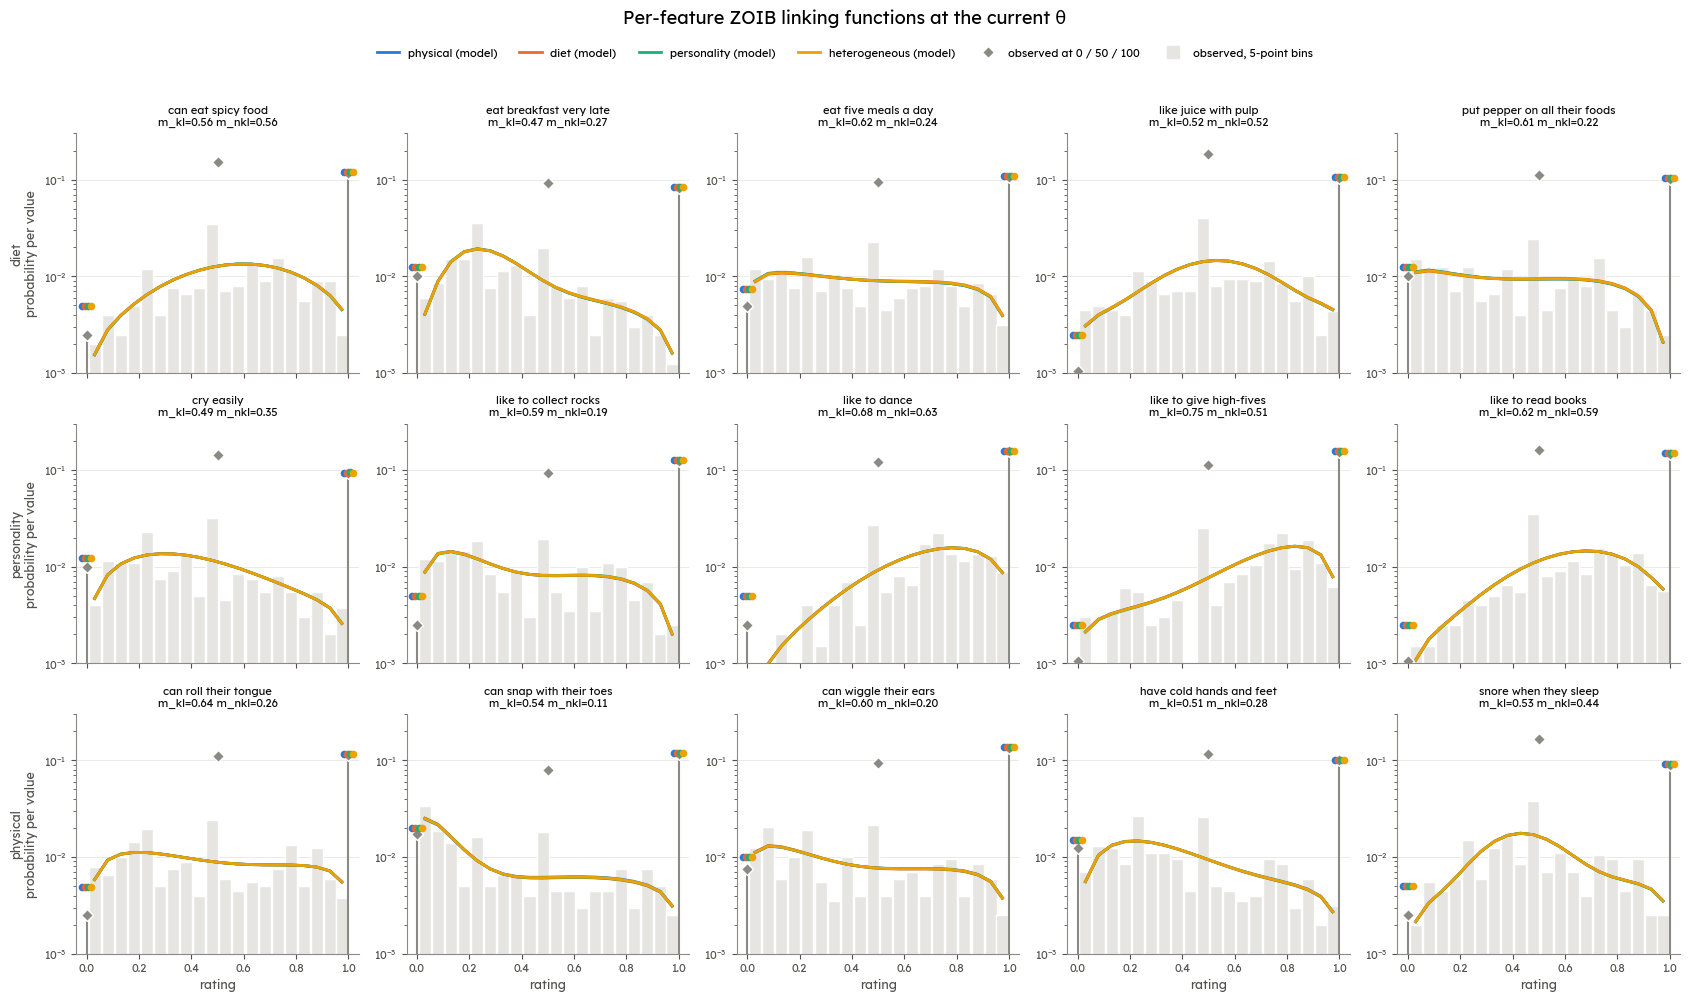

In [8]:
EDGES = np.arange(1, 101, 5)          # interior integer bins 1-5, 6-10, ..., 96-99
BINS = [np.array([k for k in range(lo, min(lo + 5, 100))]) for lo in EDGES]
CENTERS = np.array([b.mean() / 100 for b in BINS])

def model_per_value(p, j, c_pz1):
    out = []
    for b in BINS:
        x = b / 100
        comp = lambda c: (1 - p['pi0_' + c][j] - p['pi1_' + c][j]) * sbeta.pdf(x, p['a_' + c][j], p['b_' + c][j])
        out.append(np.mean(c_pz1 * comp('kl') + (1 - c_pz1) * comp('nkl')) * 0.01)
    return np.array(out)

def plot_linking(name):
    p, pz1 = P[name], THETAS[name]['pz1']
    Kall = np.concatenate([K[c] for c in CONDS])
    fig, axes = plt.subplots(3, 5, figsize=(17, 9.5), sharex=True)
    for r_i, t in enumerate(['diet', 'personality', 'physical']):
        for k_i, j in enumerate([j for j in range(J) if trait[j] == t]):
            ax = axes[r_i, k_i]
            obs_bins = np.array([np.isin(Kall[:, j], b).mean() / len(b) for b in BINS])
            ax.bar(CENTERS, obs_bins, width=0.046, color=GRID, edgecolor='white')
            for c in CONDS:
                ax.plot(CENTERS, model_per_value(p, j, pz1[c][j]), color=COND_COLOR[c], lw=2)
            for v, key in [(0, 'pi0'), (100, 'pi1')]:
                obs = np.mean(Kall[:, j] == v)
                ax.plot([v / 100] * 2, [1e-3, max(obs, 1e-3)], color=MUTED, lw=1.5)
                ax.plot(v / 100, max(obs, 1.05e-3), 'D', color=MUTED, ms=6, mec='white')
                for i_c, c in enumerate(CONDS):
                    fitted = pz1[c][j] * p[key + '_kl'][j] + (1 - pz1[c][j]) * p[key + '_nkl'][j]
                    ax.plot(v / 100 + (i_c - 1.5) * 0.012, fitted, 'o', color=COND_COLOR[c], ms=4.5, zorder=4)
            ax.plot(0.5, max(np.mean(Kall[:, j] == 50), 1.05e-3), 'D', color=MUTED, ms=6, mec='white', zorder=4)
            ax.set_xlim(-0.04, 1.04); ax.set_yscale('log'); ax.set_ylim(1e-3, 0.3); grid_y(ax)
            ax.set_title(f"{features[j]}\nm_kl={p['m_kl'][j]:.2f} m_nkl={p['m_nkl'][j]:.2f}", fontsize=8, color=TEXT_1)
        axes[r_i, 0].set_ylabel(f"{t}\nprobability per value", color=TEXT_2)
    for ax in axes[-1]:
        ax.set_xlabel('rating')
    leg = [Line2D([], [], color=COND_COLOR[c], lw=2, label=f'{c} (model)') for c in CONDS]
    leg += [Line2D([], [], marker='D', ls='', color=MUTED, mec='white', ms=6, label='observed at 0 / 50 / 100'),
            Line2D([], [], marker='s', ls='', color=GRID, ms=9, label='observed, 5-point bins')]
    fig.legend(handles=leg, loc='upper center', ncol=6, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f"Per-feature ZOIB linking functions at the {name}", y=1.05, fontsize=13)
    fig.tight_layout(); plt.show()

plot_linking('current θ')

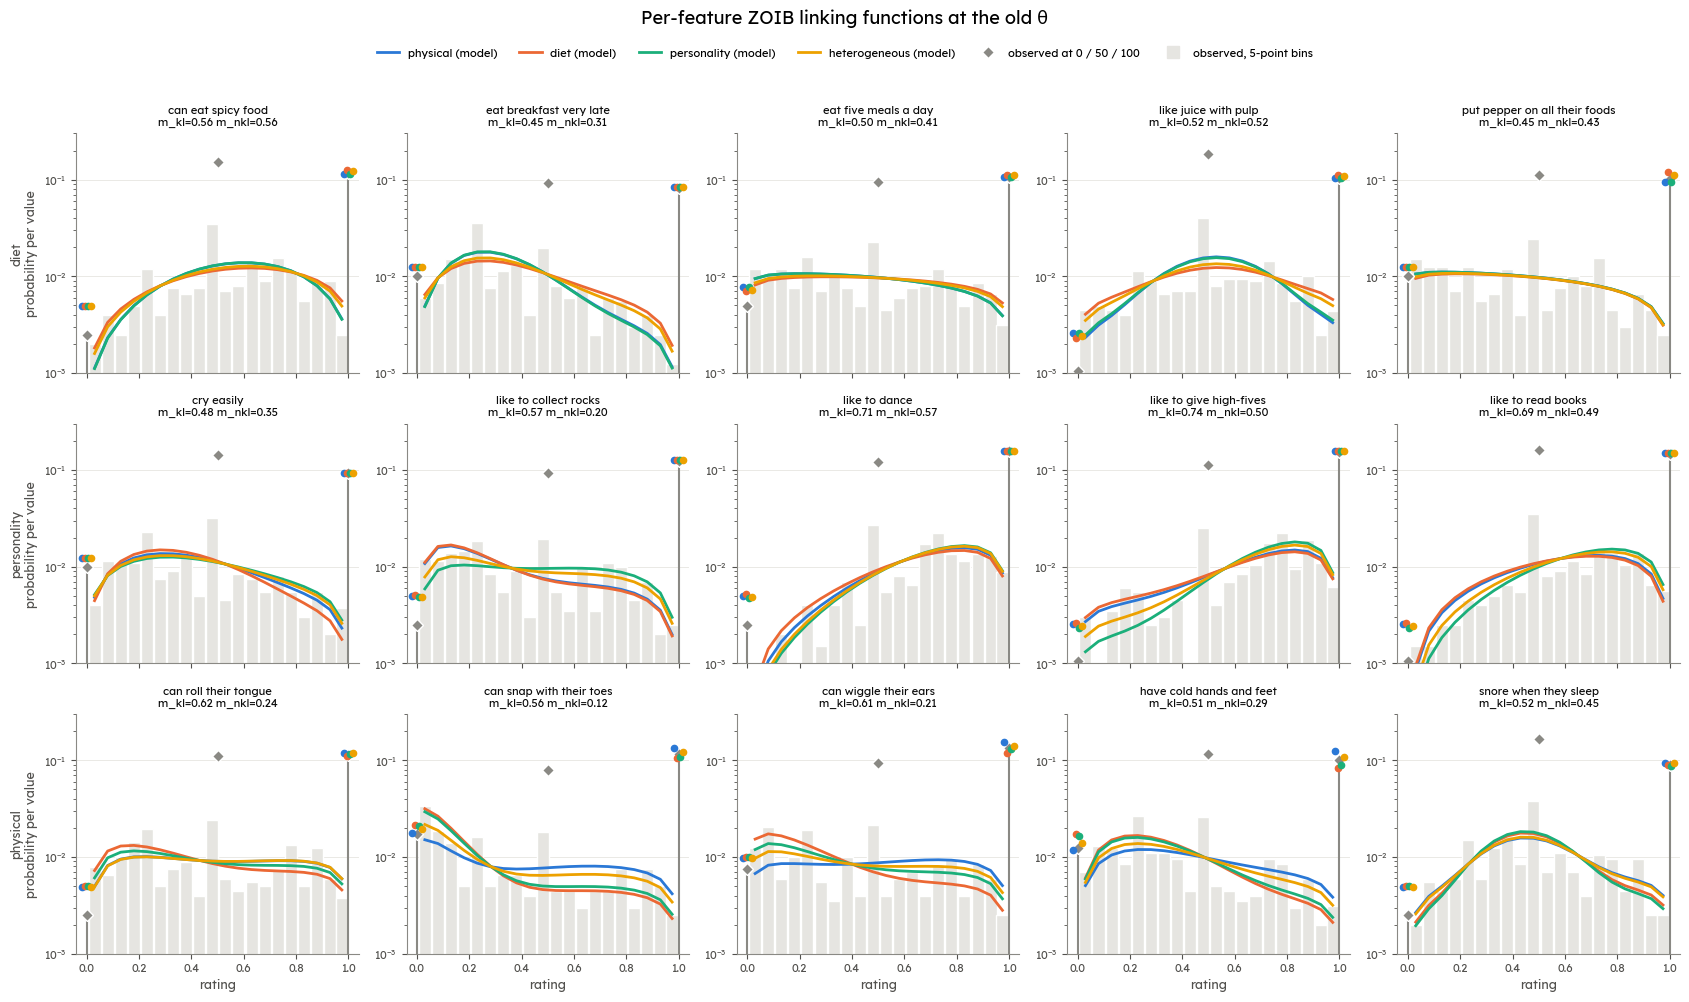

In [9]:
plot_linking('old θ')

## 5b. The two components of each feature, separately

Each feature's linking function is built from two components; this shows them **unmixed**, before
coherence weights them. For each component c:
- **curve**: its Beta part, drawn as a density and scaled by the share of answers it covers,
  (1 − π0_c − π1_c)·Beta(r | m_c, κ_c), so the area under the curve is the probability of a non-0,
  non-100 answer from that component;
- **text**: its point masses, P(0) = π0_c and P(100) = π1_c;
- **dashed line**: the component's Beta mean m_c.

Blue = kind-linked (kl), orange = not kind-linked (nkl). The grey histogram is the feature's pooled ratings
(density, excluding exact 0 and 100) for reference. Where the two curves overlap and the point masses
match, the feature's ratings can't depend on coherence.

**Yellow** = the feature's final linking function: the two Beta parts mixed by coherence, using the coherence averaged over participants across the four conditions (same scaling, so the point masses P(0) and P(100) are not in the curve; they're in section 5c).

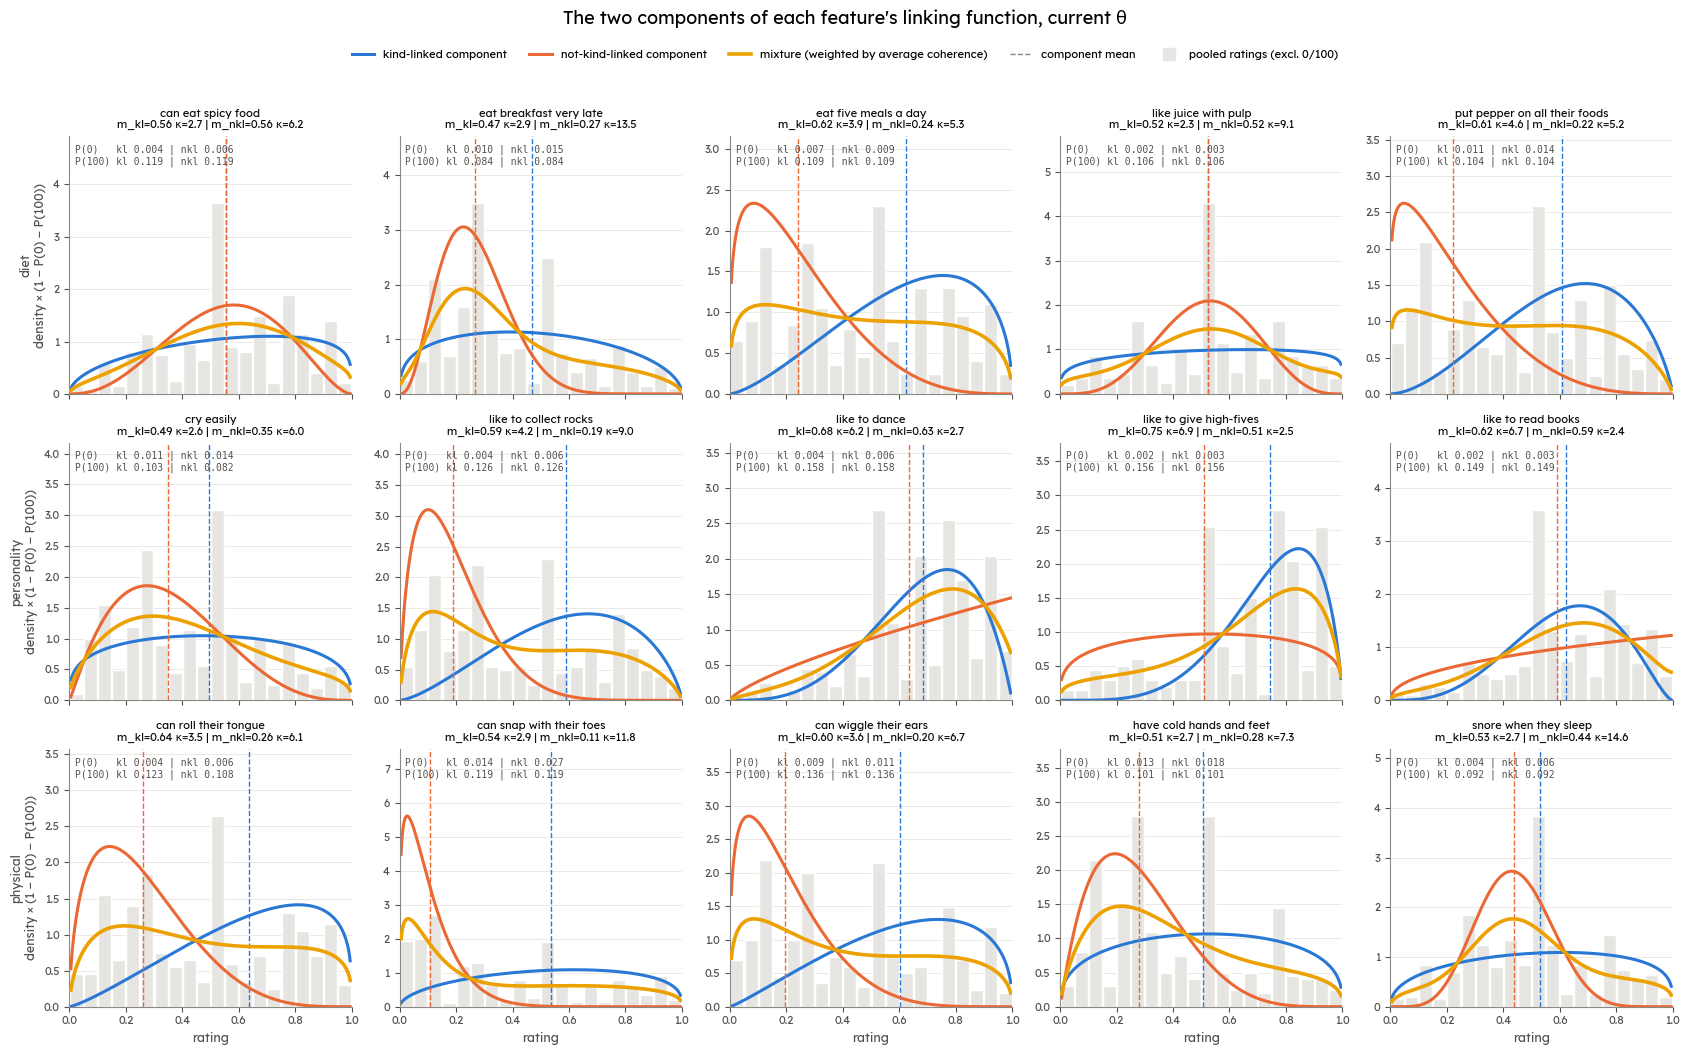

In [23]:
XG = np.linspace(0.005, 0.995, 400)
HBINS = np.linspace(0, 1, 21)

MIX_COLOR = '#eda100'

def plot_components(name):
    p = P[name]
    Kall = np.concatenate([K[c] for c in CONDS])
    # coherence averaged over participants: the mixture is linear in coherence, so the average of the
    # four conditions' mixtures equals the mixture at this average coherence
    n_c = np.array([K[c].shape[0] for c in CONDS], float)
    pz1_bar = np.sum([n * THETAS[name]['pz1'][c] for n, c in zip(n_c, CONDS)], axis=0) / n_c.sum()
    fig, axes = plt.subplots(3, 5, figsize=(17, 10), sharex=True)
    for r_i, t in enumerate(['diet', 'personality', 'physical']):
        for k_i, j in enumerate([j for j in range(J) if trait[j] == t]):
            ax = axes[r_i, k_i]
            interior = Kall[:, j][(Kall[:, j] > 0) & (Kall[:, j] < 100)] / 100
            w_int = len(interior) / len(Kall[:, j])
            h, _ = np.histogram(interior, bins=HBINS, density=True)
            ax.bar(0.5 * (HBINS[1:] + HBINS[:-1]), h * w_int, width=0.046, color=GRID, edgecolor='white')
            top = h.max() * w_int
            for c in ('kl', 'nkl'):
                w = 1 - p['pi0_' + c][j] - p['pi1_' + c][j]
                y = w * sbeta.pdf(XG, p['a_' + c][j], p['b_' + c][j])
                ax.plot(XG, y, color=CLS_COLOR[c], lw=2.2, label=f'{c} component')
                ax.axvline(p['m_' + c][j], color=CLS_COLOR[c], lw=1, ls='--')
                top = max(top, y.max())
            ymix = (pz1_bar[j] * (1 - p['pi0_kl'][j] - p['pi1_kl'][j]) * sbeta.pdf(XG, p['a_kl'][j], p['b_kl'][j])
                    + (1 - pz1_bar[j]) * (1 - p['pi0_nkl'][j] - p['pi1_nkl'][j]) * sbeta.pdf(XG, p['a_nkl'][j], p['b_nkl'][j]))
            ax.plot(XG, ymix, color=MIX_COLOR, lw=2.6, zorder=4)
            top = max(top, ymix.max())
            ax.set_ylim(0, 1.35 * top); ax.set_xlim(0, 1); grid_y(ax)
            txt = (f"P(0)   kl {p['pi0_kl'][j]:.3f} | nkl {p['pi0_nkl'][j]:.3f}\n"
                   f"P(100) kl {p['pi1_kl'][j]:.3f} | nkl {p['pi1_nkl'][j]:.3f}")
            ax.text(0.02, 0.97, txt, transform=ax.transAxes, va='top', fontsize=7, color=TEXT_2, family='monospace')
            ax.set_title(f"{features[j]}\nm_kl={p['m_kl'][j]:.2f} κ={p['kappa_kl'][j]:.1f} | "
                         f"m_nkl={p['m_nkl'][j]:.2f} κ={p['kappa_nkl'][j]:.1f}", fontsize=8, color=TEXT_1)
        axes[r_i, 0].set_ylabel(f"{t}\ndensity × (1 − P(0) − P(100))", color=TEXT_2)
    for ax in axes[-1]:
        ax.set_xlabel('rating')
    leg = [Line2D([], [], color=CLS_COLOR['kl'], lw=2.2, label='kind-linked component'),
           Line2D([], [], color=CLS_COLOR['nkl'], lw=2.2, label='not-kind-linked component'),
           Line2D([], [], color=MIX_COLOR, lw=2.6, label='mixture (weighted by average coherence)'),
           Line2D([], [], color=MUTED, lw=1, ls='--', label='component mean'),
           Line2D([], [], marker='s', ls='', color=GRID, ms=9, label='pooled ratings (excl. 0/100)')]
    fig.legend(handles=leg, loc='upper center', ncol=5, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f"The two components of each feature's linking function, {name}", y=1.05, fontsize=13)
    fig.tight_layout(); plt.show()

plot_components('current θ')

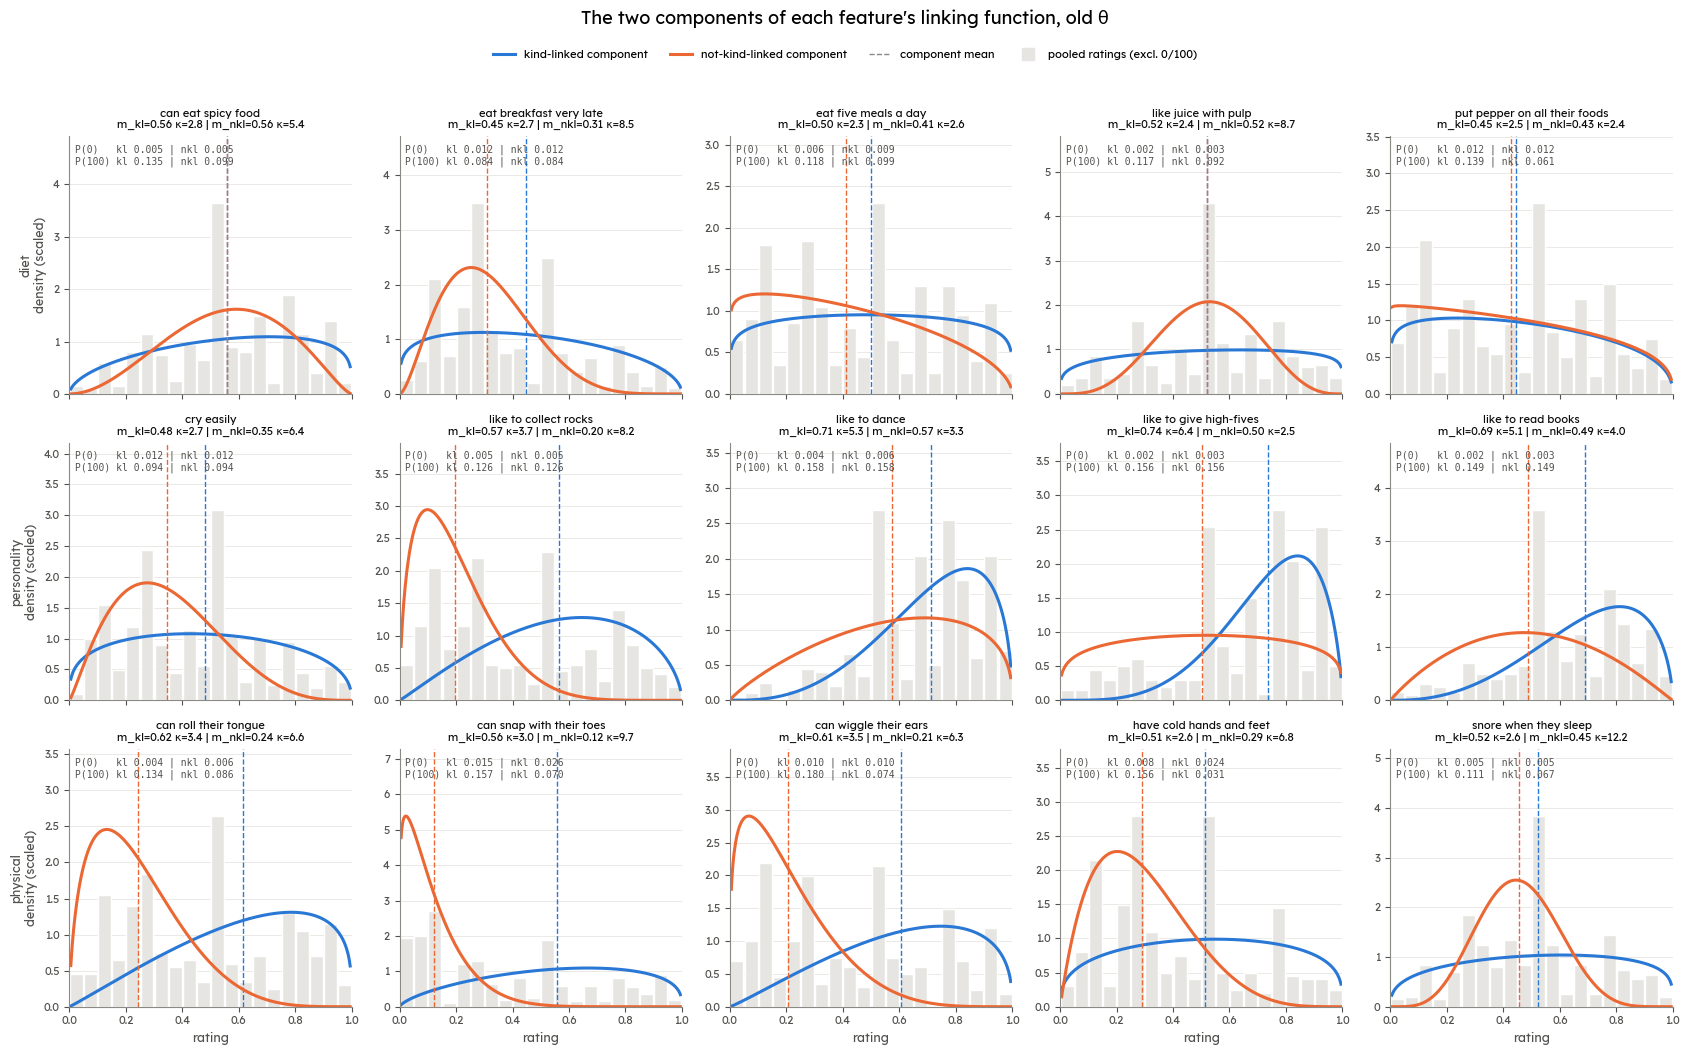

In [11]:
plot_components('old θ')

### 5c. The point masses: P(0) and P(100) per feature

The component figures above show only the Beta part; the point masses are probabilities, not densities, so
they get their own figure. For each feature: the kind-linked (blue) and not-kind-linked (orange) component's
P(0) and P(100); the observed share of exact 0s / 100s pooled over conditions (grey diamond); and the share
the model predicts after coherence mixes the two components, averaged over participants (black tick).
By the constraints, blue ≥ orange for P(100) and blue ≤ orange for P(0).

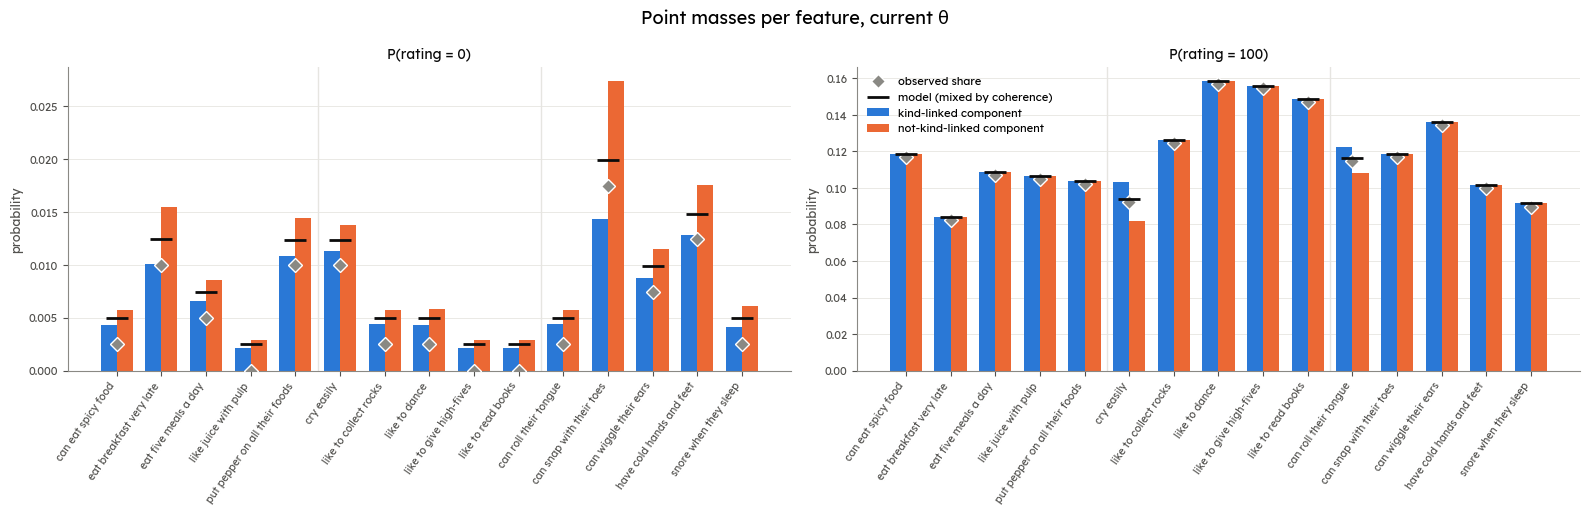

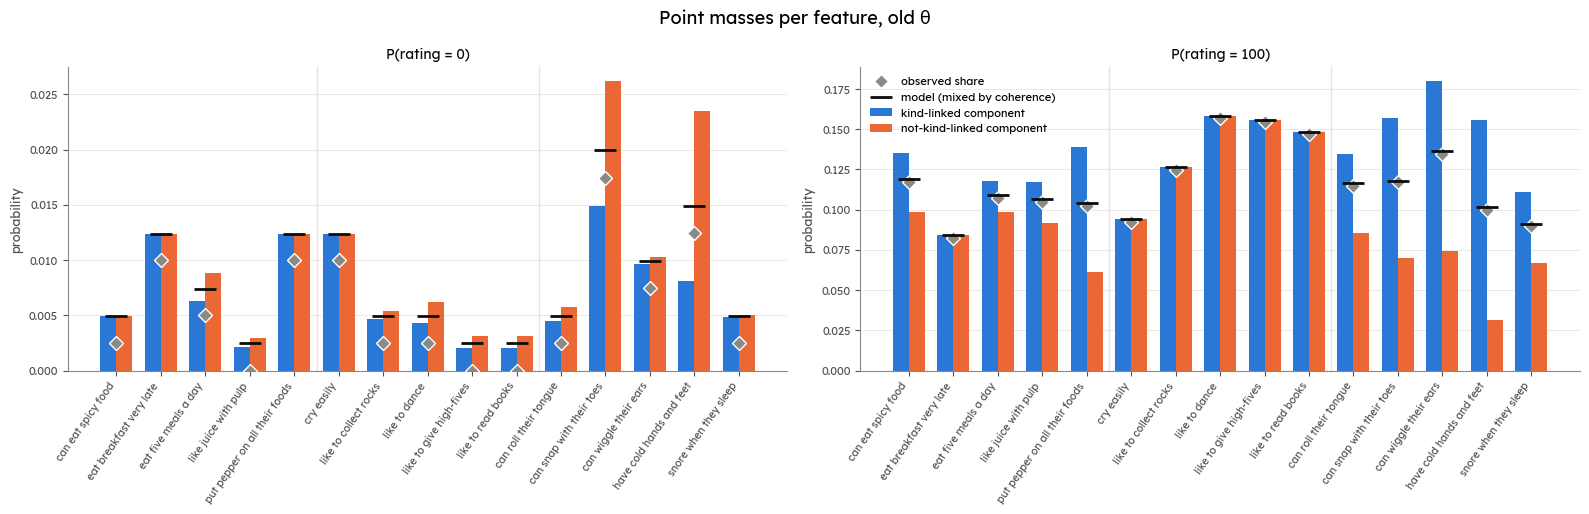

In [21]:
def plot_point_masses(name):
    p, pz1 = P[name], THETAS[name]['pz1']
    order_pm = [j for t in ['diet', 'personality', 'physical'] for j in range(J) if trait[j] == t]
    Kall = np.concatenate([K[c] for c in CONDS])
    n_c = np.array([K[c].shape[0] for c in CONDS], float)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), sharex=True)
    for ax, (val, key, lab) in zip(axes, [(0, 'pi0', 'P(rating = 0)'), (100, 'pi1', 'P(rating = 100)')]):
        x = np.arange(J); w = 0.36
        ax.bar(x - w / 2, p[key + '_kl'][order_pm], w, color=CLS_COLOR['kl'], label='kind-linked component')
        ax.bar(x + w / 2, p[key + '_nkl'][order_pm], w, color=CLS_COLOR['nkl'], label='not-kind-linked component')
        obs = np.mean(Kall == val, axis=0)[order_pm]
        mix = np.array([np.sum(n_c * np.array([pz1[c][j] * p[key + '_kl'][j] + (1 - pz1[c][j]) * p[key + '_nkl'][j]
                                               for c in CONDS])) / n_c.sum() for j in order_pm])
        ax.plot(x, obs, 'D', color=MUTED, ms=7, mec='white', zorder=4, label='observed share')
        ax.plot(x, mix, '_', color=TEXT_1, ms=16, mew=2, zorder=5, label='model (mixed by coherence)')
        for b in (4.5, 9.5):
            ax.axvline(b, color=GRID, lw=1)
        ax.set_xticks(x); ax.set_xticklabels([features[j] for j in order_pm], rotation=55, ha='right', fontsize=7.5)
        ax.set_ylabel('probability'); ax.set_title(f"{lab}", color=TEXT_1); grid_y(ax)
    axes[1].legend(loc='upper left', fontsize=8)
    fig.suptitle(f"Point masses per feature, {name}", fontsize=13)
    fig.tight_layout(); plt.show()

plot_point_masses('current θ')
plot_point_masses('old θ')

## 6. Predicted vs empirical mean ratings

Mean rating implied by the ZOIB mixture in each condition × feature cell vs the empirical mean, with the R²
split (overall / between-feature / within-feature) and the memorization baseline (each cell predicted by its
feature's pooled mean). **θ is not refit here**, so this is a first look only.

In [12]:
E = np.stack([np.asarray(raw[c]).mean(0) for c in CONDS])
Nc = np.array([raw[c].shape[0] for c in CONDS])[:, None]
pooled = (E * Nc).sum(0) / Nc.sum()
r2 = lambda p, e: 1 - np.sum((e - p) ** 2) / np.sum((e - e.mean()) ** 2)
def summary(label, Pm):
    Pb, Eb = Pm.mean(0), E.mean(0)
    return {'model': label, 'R2 overall': r2(Pm.ravel(), E.ravel()), 'R2 between': r2(Pb, Eb),
            'R2 within': r2((Pm - Pb).ravel(), (E - Eb).ravel())}
PRED = {name: np.stack([lk.expected_rating(lk.unpack(jnp.asarray(fits[name])), THETAS[name]['pz1'][c]) for c in CONDS])
        for name in THETAS}
pd.DataFrame([summary(f'per-feature ZOIB, {n}', PRED[n]) for n in THETAS] +
             [summary('memorize: pooled feature mean', np.tile(pooled, (len(CONDS), 1)))]).set_index('model').round(3)

,R2 overall,R2 between,R2 within
model,,,
"per-feature ZOIB, current θ",0.770,0.999,0.011
"per-feature ZOIB, old θ",0.815,0.999,0.204
memorize: pooled feature mean,0.768,1.000,0.000


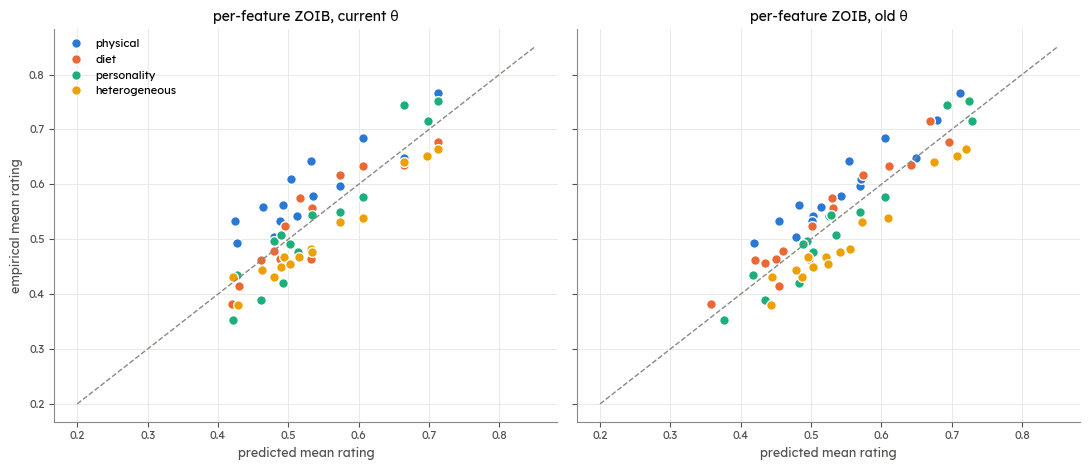

In [13]:
fig, axes = plt.subplots(1, len(THETAS), figsize=(11, 4.8), sharex=True, sharey=True)
for ax, name in zip(axes, THETAS):
    for i, c in enumerate(CONDS):
        ax.plot(PRED[name][i], E[i], 'o', color=COND_COLOR[c], ms=7, mec='white', mew=1, label=c)
    ax.plot([0.2, 0.85], [0.2, 0.85], color=MUTED, lw=1, ls='--')
    ax.set_xlabel('predicted mean rating'); ax.set_title(f"per-feature ZOIB, {name}", color=TEXT_1); grid_xy(ax)
axes[0].set_ylabel('empirical mean rating'); axes[0].legend(loc='upper left')
fig.tight_layout(); plt.show()

## What the checks show

- **Reliability (1):** the batched per-feature fit reaches the same optimum from every seed, at both θ
  values, in ~0.6 s per fit. A plain joint multi-start over all 120 parameters never reaches it at the
  current θ (median 3 units worse) and only rarely at the old θ.
- **P(0) and P(100) (2):** the per-feature point masses follow the between-feature differences in how
  often people answer 0 or 100, which the shared-π version couldn't. Within a feature, condition
  differences in 100s can only come from coherence, so they're small at the current θ.
- **50 is badly underfit (2, 5):** 8–18% of each feature's ratings are exactly 50, but the Beta part gives
  the value 50 only ~1%. The fit compensates by pulling Beta curves toward 0.5. In "can eat spicy food",
  "like juice with pulp" and "snore when they sleep", both classes' means sit at ~0.52–0.56 (collapsed),
  which matches the risk of dropping the 50 point mass.
- **Constraints (3):** all hold (ordered means and point masses, a, b > 1, κ ≤ ~15). **At the current θ the
  two classes have the same P(100) in 13 of 15 features:** with flat coherence the data can't tell the
  classes apart there, and the prior settles on equal. At the old θ, where coherence varies, that drops to 6.
- **Proper distributions (4):** every component sums to 1 to ~1e-11.
- **Predicted means (6), θ not refit:** at the old θ the per-feature ZOIB gives R² 0.815 overall and
  **within-feature R² 0.20**, the best so far (0.12 for the shared-π ZOIB and 0.07 for the old free linking
  at the same θ). It also beats the memorization baseline (0.768). At the current θ it's the memorization
  baseline again (within-feature 0.01). Between-feature R² is ~1.0 under both θ: the per-feature linking
  reproduces feature levels exactly, as expected with 8 parameters per feature.

## 7. The most recent run: VBMC-fitted θ with the ZOIB linking

The sections above hold θ fixed at two earlier fits. This one uses the θ that VBMC inferred **with** the
ZOIB linking (`run_parameter_estimation.py study9-zoib`, posterior median, `results/study9-fit-zoib/`), and
the per-feature linking that run saved at that θ (`fitted-link-zoib.npz`, the same fit `linking.fit` gives
there). Plotted the same way as sections 5 and 5b: the mixtures per condition against the data, then each
feature's two components unmixed.

In [17]:
RUN_NAME = 'VBMC fit θ (study9-fit-zoib)'
zr = np.load(os.path.join('results', 'study9-fit-zoib', 'fitted-link-zoib.npz'), allow_pickle=True)
assert [str(f) for f in zr['feature_names']] == features
ls_r, mu_r, sig_r, b_r = [float(v) for v in zr['theta']]
THETAS[RUN_NAME] = dict(theta=(ls_r, mu_r, sig_r, b_r),
                        pz1={c: np.asarray(v) for c, v in inf.prior_pz1_modes(geom, ls_r, mu_r, sig_r, beta_speaker=b_r).items()})
P[RUN_NAME] = lk.params_to_numpy(lk.unpack(jnp.asarray(zr['link_theta'])))
_pz = THETAS[RUN_NAME]['pz1']
print(f"{RUN_NAME}: ls={ls_r:.3f} mu_0={mu_r:+.3f} sigma={sig_r:.3f} speaker beta={b_r:.3f}  "
      f"pz1 range {min(v.min() for v in _pz.values()):.3f}-{max(v.max() for v in _pz.values()):.3f}")

VBMC fit θ (study9-fit-zoib): ls=0.344 mu_0=+1.293 sigma=0.522 speaker beta=25.931  pz1 range 0.799-0.845


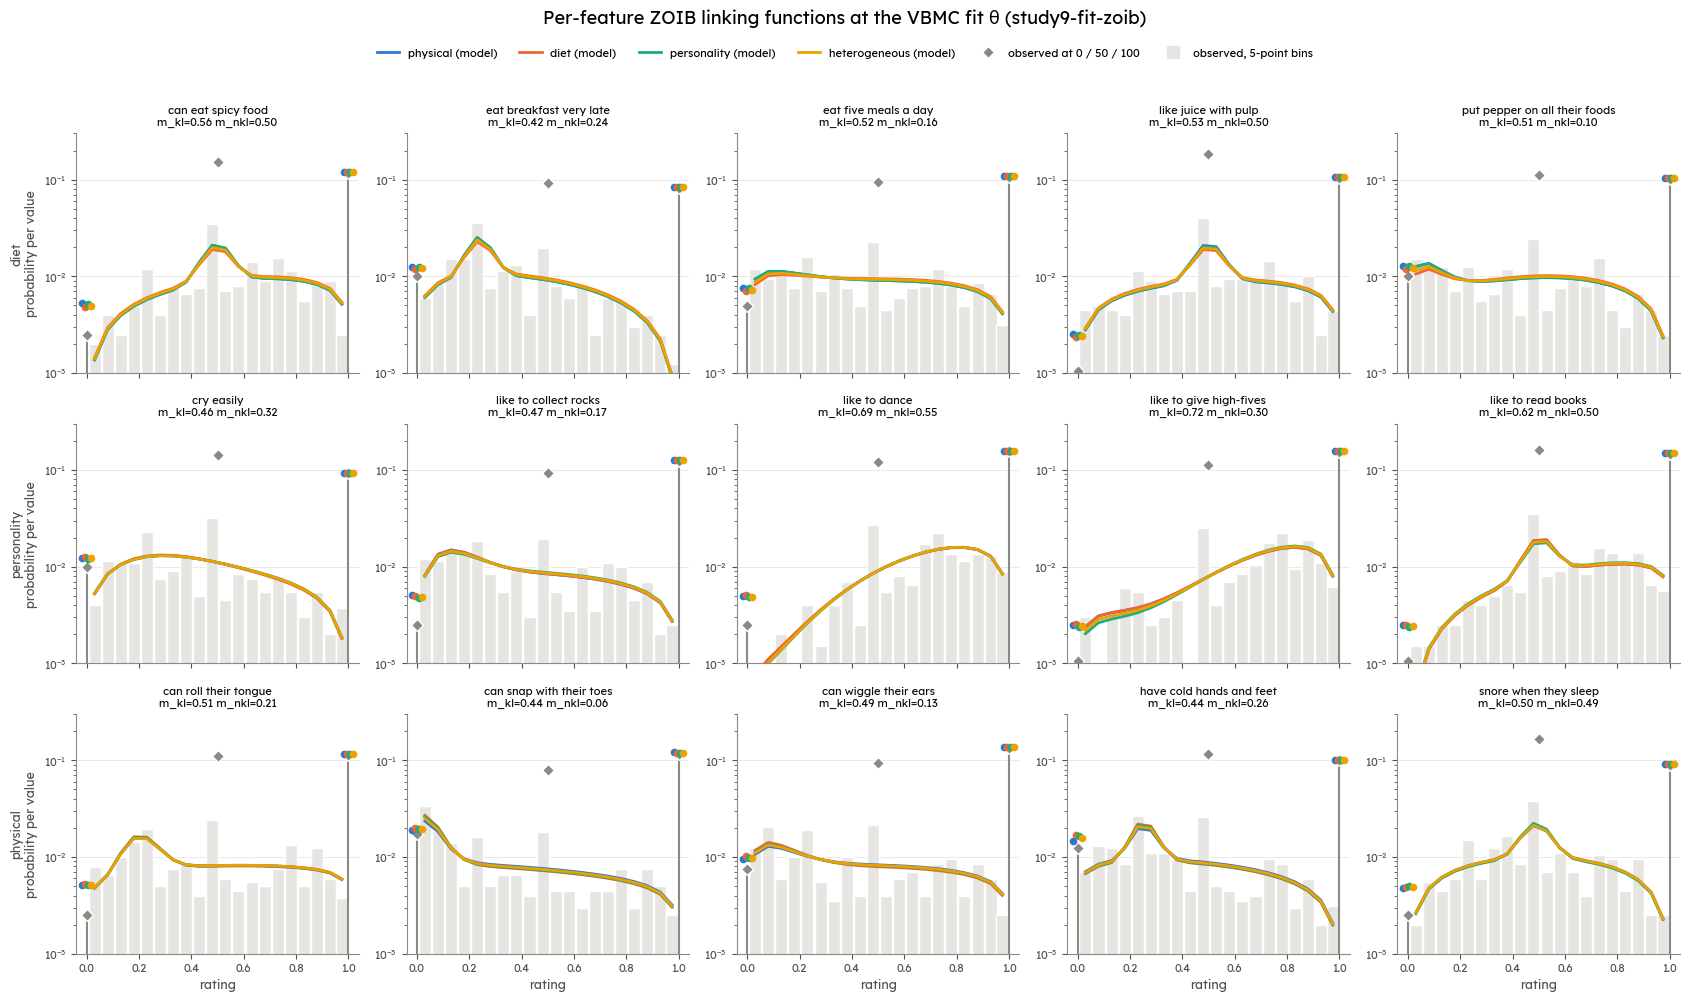

In [18]:
plot_linking(RUN_NAME)

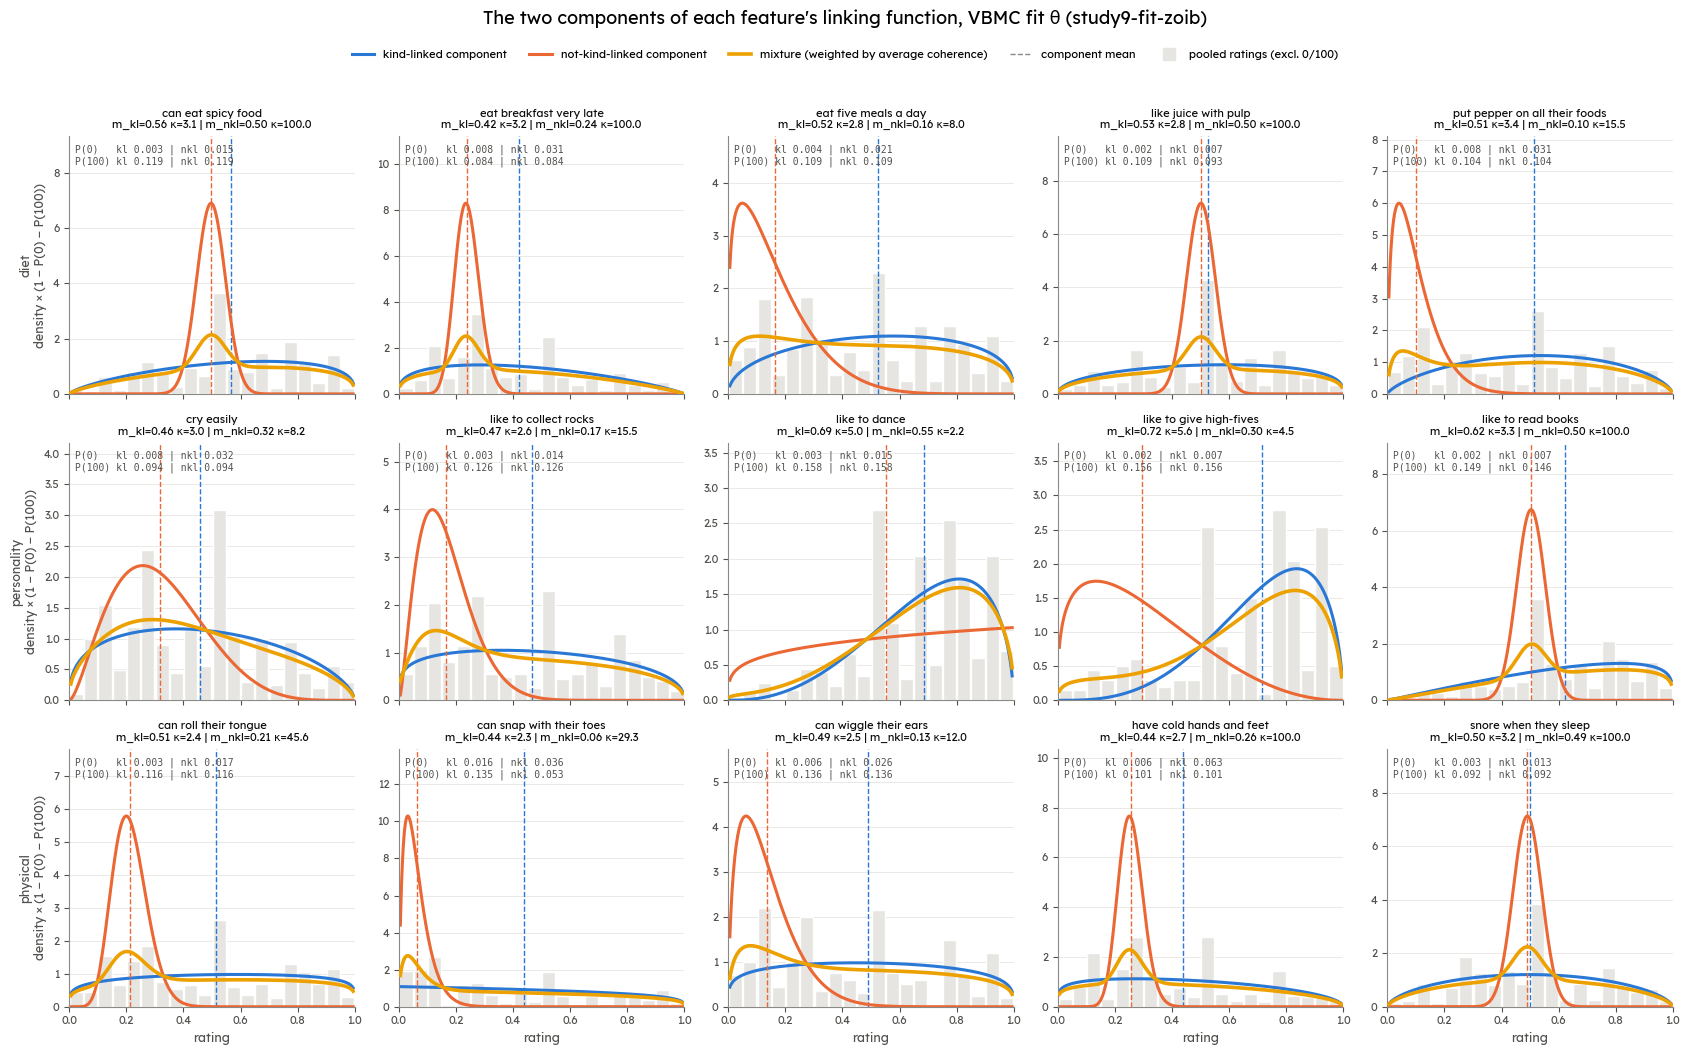

In [24]:
plot_components(RUN_NAME)

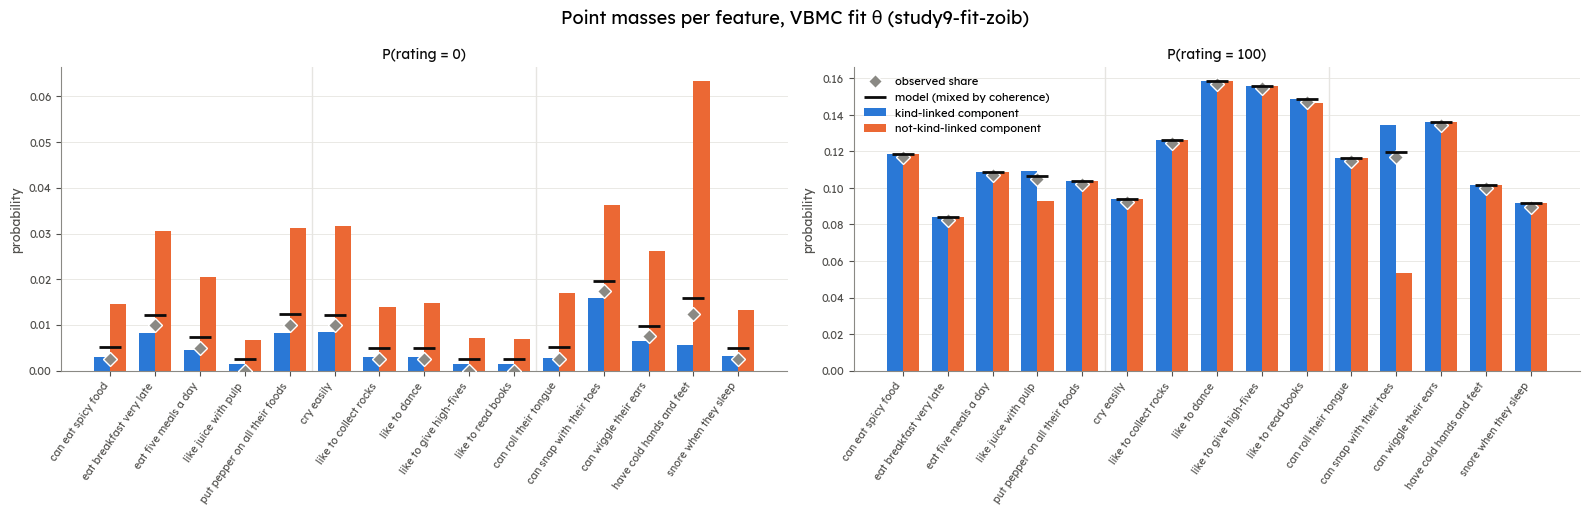

In [22]:
plot_point_masses(RUN_NAME)